
3# Section 3.1 — Data Preparation

In [116]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    brier_score_loss,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
RANDOM_STATE = 22

In [117]:
df2 = pd.read_csv(
    r"c:\\Users\\user\\Desktop\\Msc Data Science\\Advanced Decision Making\\Week 12\\sample\\online_shoppers_intention.csv"
)
df2.shape

(12330, 18)

In [118]:
df2.isnull().sum()

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

In [119]:
df2["Revenue"].value_counts(normalize=True).mul(100).round(2)

Revenue
False    84.53
True     15.47
Name: proportion, dtype: float64

In [120]:
df2["Revenue"] = df2["Revenue"].astype(int)
df2["Weekend"] = df2["Weekend"].astype(int)

X = pd.get_dummies(df2.drop(columns=["Revenue"]))
y = df2["Revenue"]

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (12330, 28)
Shape of y: (12330,)


In [121]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("Train class balance:", y_train.mean().round(4))
print("Test  class balance:", y_test.mean().round(4))

X_train: (9247, 28)
X_test : (3083, 28)
Train class balance: 0.1548
Test  class balance: 0.1547


In [122]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [123]:
y

0        0
1        0
2        0
3        0
4        0
        ..
12325    0
12326    0
12327    0
12328    0
12329    0
Name: Revenue, Length: 12330, dtype: int64

# Section 3.2 — Exploratory Data Analysis

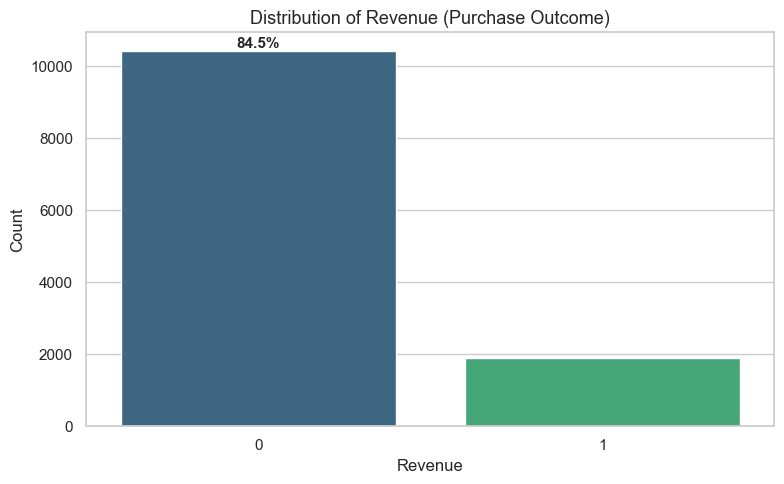

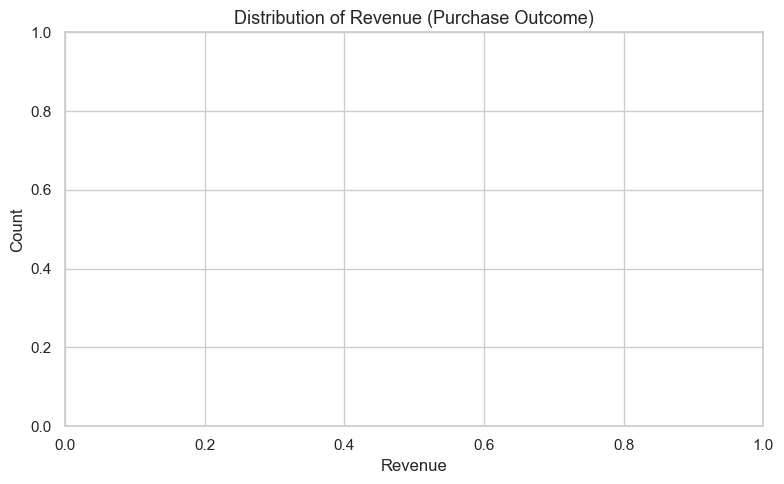

In [124]:
plt.figure(figsize=(8, 5))
total = float(len(df2))
ax = sns.countplot(x="Revenue", data=df2, hue="Revenue", palette="viridis", legend=False)
for p in ax.patches:
    pct = f"{100 * p.get_height() / total:.1f}%"
    x = p.get_x() + p.get_width() / 2
    y_ = p.get_height()
    ax.annotate(pct, (x, y_), ha="center", va="bottom", fontsize=11, fontweight="bold")
    plt.title("Distribution of Revenue (Purchase Outcome)", fontsize=13)
    plt.xlabel("Revenue")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

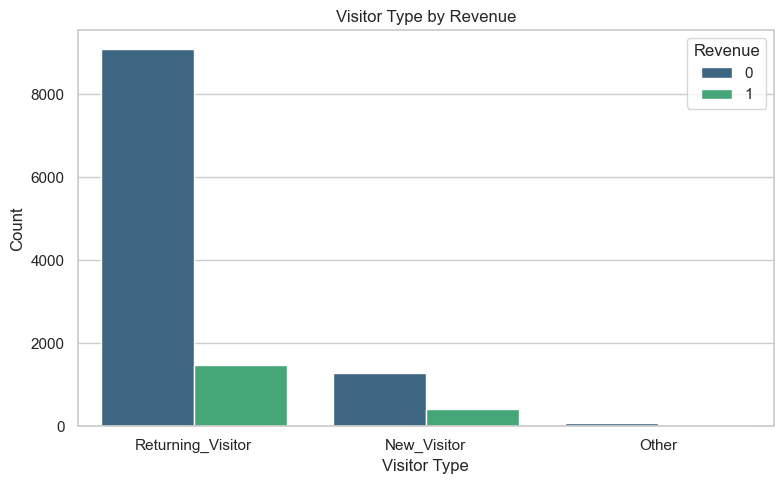

In [126]:
plt.figure(figsize=(8, 5))
sns.countplot(x="VisitorType", data=df2, hue="Revenue", palette="viridis")
plt.title("Visitor Type by Revenue")
plt.xlabel("Visitor Type")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

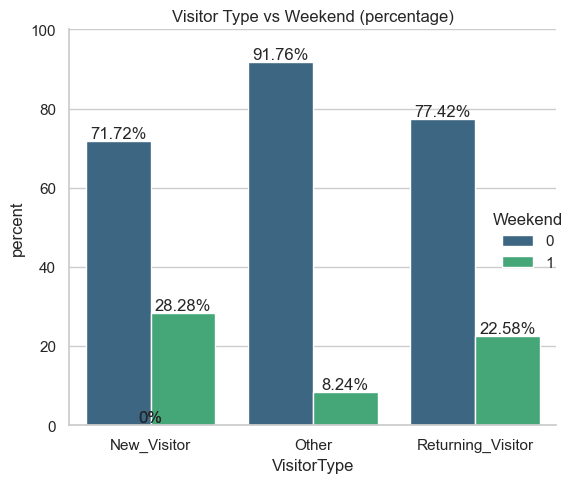

In [127]:
x, y_col = "VisitorType", "Weekend"
df1 = df2.groupby(x)[y_col].value_counts(normalize=True).mul(100).rename("percent").reset_index()
g = sns.catplot(x=x, y="percent", hue=y_col, kind="bar", data=df1, palette="viridis")
g.ax.set_ylim(0, 100)
for p in g.ax.patches:
    txt = f"{round(p.get_height(), 2)}%"
    g.ax.text(p.get_x() + p.get_width() / 2, p.get_height(), txt, ha="center", va="bottom")
plt.title("Visitor Type vs Weekend (percentage)")
plt.tight_layout()
plt.show()

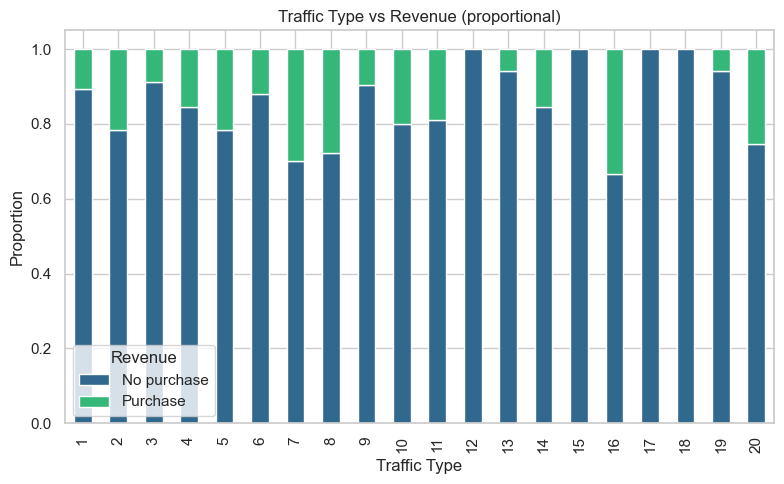

In [128]:
colors = sns.color_palette("viridis", 2)
ct = pd.crosstab(df2["TrafficType"], df2["Revenue"])
ct.div(ct.sum(1).astype(float), axis=0).plot(
    kind="bar", stacked=True, color=colors, legend=True
)
plt.title("Traffic Type vs Revenue (proportional)")
plt.xlabel("Traffic Type")
plt.ylabel("Proportion")
plt.legend(title="Revenue", labels=["No purchase", "Purchase"])
plt.tight_layout()
plt.show()

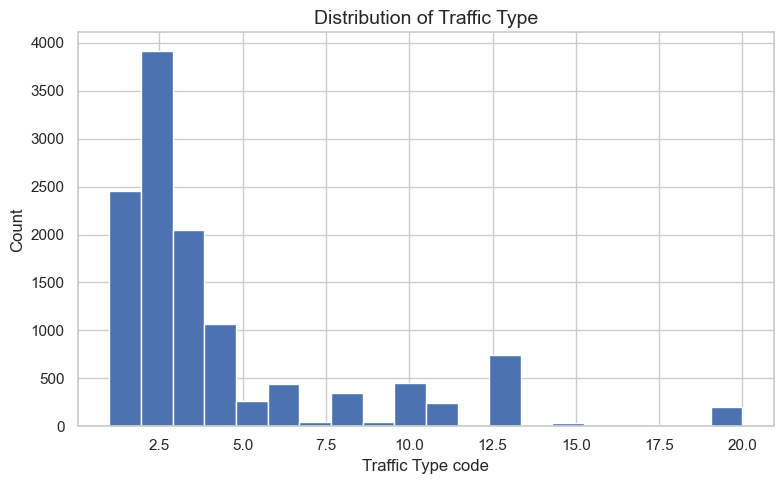

In [129]:
plt.hist(df2["TrafficType"], bins=20)
plt.title("Distribution of Traffic Type", fontsize=14)
plt.xlabel("Traffic Type code")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

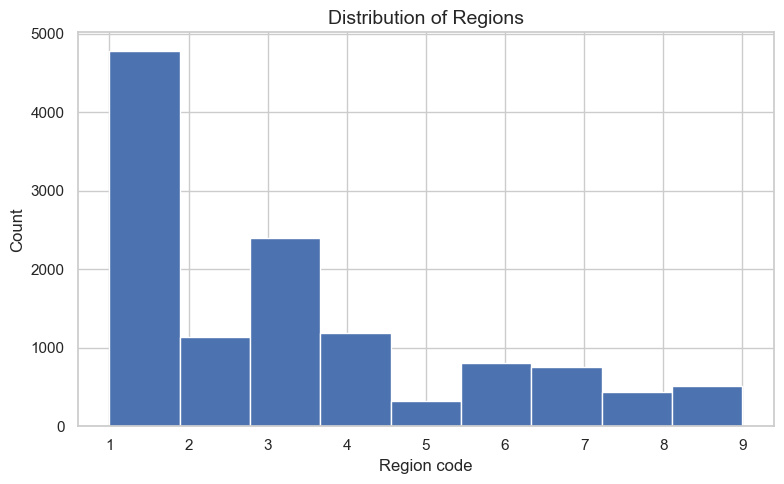

In [130]:
plt.hist(df2["Region"], bins=9)
plt.title("Distribution of Regions", fontsize=14)
plt.xlabel("Region code")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

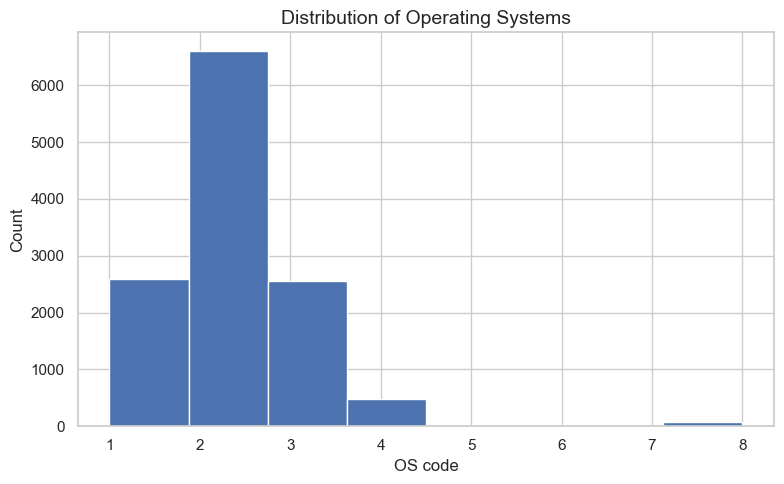

In [131]:
plt.hist(df2["OperatingSystems"], bins=8)
plt.title("Distribution of Operating Systems", fontsize=14)
plt.xlabel("OS code")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

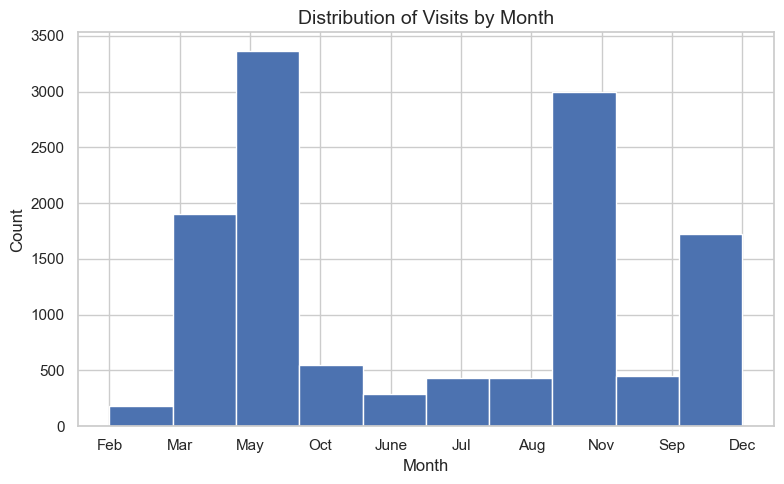

In [132]:
plt.hist(df2["Month"])
plt.title("Distribution of Visits by Month", fontsize=14)
plt.xlabel("Month")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

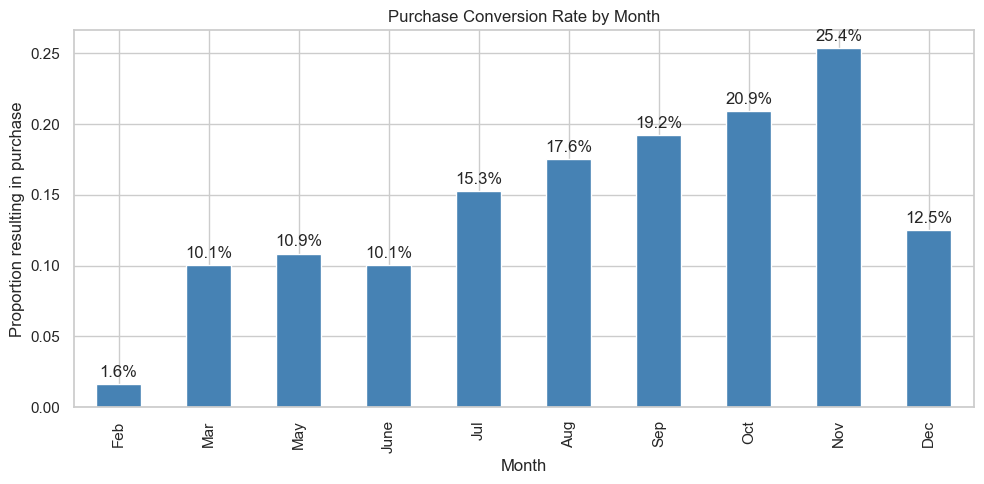

In [133]:
month_order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly = df2.groupby("Month")["Revenue"].mean().reindex(month_order).dropna()

plt.figure(figsize=(10, 5))
monthly.plot(kind="bar", color="steelblue")
for i, v in enumerate(monthly):
    plt.text(i, v + 0.005, f"{v:.1%}", ha="center")
plt.title("Purchase Conversion Rate by Month")
plt.xlabel("Month")
plt.ylabel("Proportion resulting in purchase")
plt.tight_layout()
plt.show()

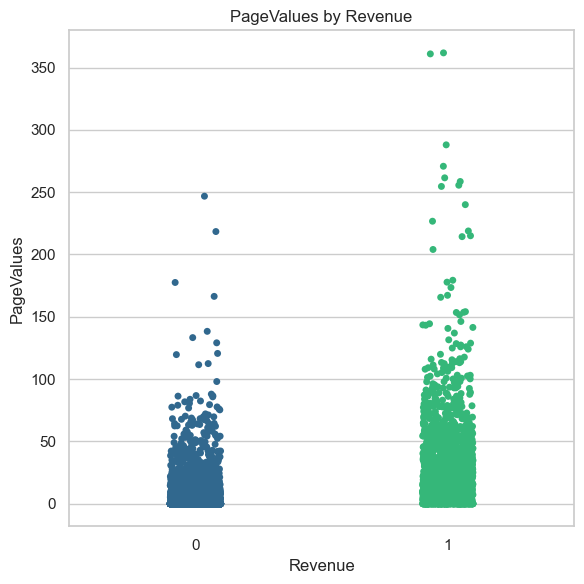

In [134]:
plt.figure(figsize=(6, 6))
sns.stripplot(x="Revenue", y="PageValues", hue="Revenue",
              data=df2, palette="viridis", legend=False)
plt.title("PageValues by Revenue")
plt.tight_layout()
plt.show()

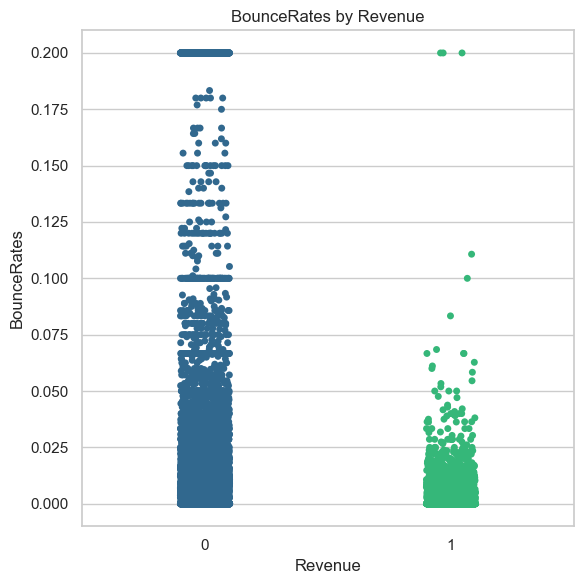

In [135]:
plt.figure(figsize=(6, 6))
sns.stripplot(x="Revenue", y="BounceRates", hue="Revenue",
              data=df2, palette="viridis", legend=False)
plt.title("BounceRates by Revenue")
plt.tight_layout()
plt.show()

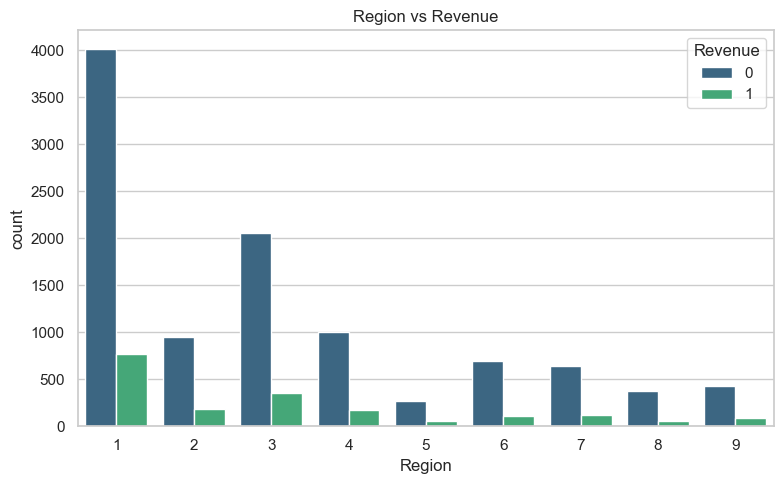

In [136]:
plt.figure(figsize=(8, 5))
sns.countplot(x="Region", hue="Revenue", data=df2, palette="viridis")
plt.title("Region vs Revenue")
plt.tight_layout()
plt.show()

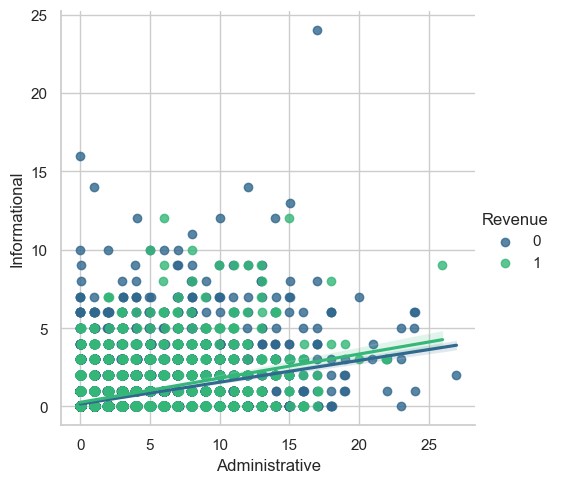

In [137]:
sns.lmplot(x="Administrative", y="Informational", data=df2,
           x_jitter=0.05, hue="Revenue", palette="viridis")
plt.show()

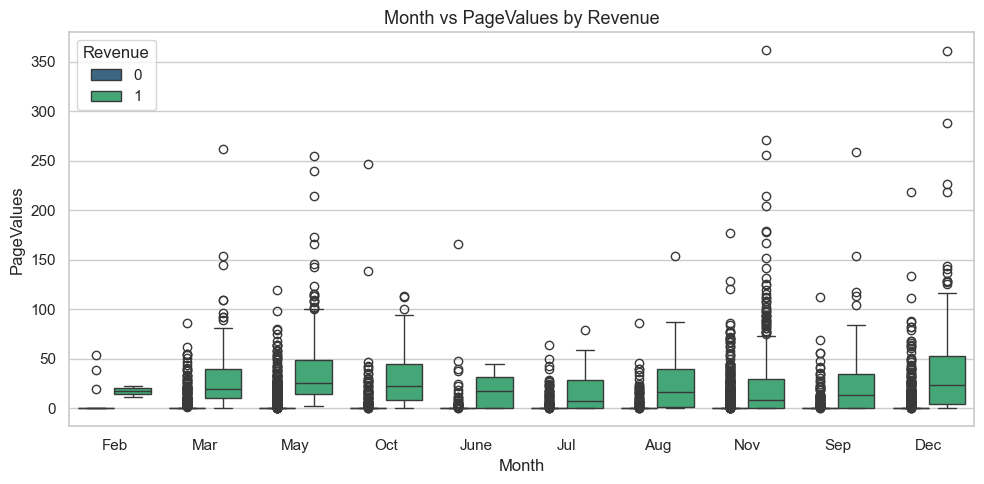

In [138]:
plt.figure(figsize=(10, 5))
sns.boxplot(x="Month", y="PageValues", hue="Revenue", data=df2, palette="viridis")
plt.title("Month vs PageValues by Revenue", fontsize=13)
plt.tight_layout()
plt.show()

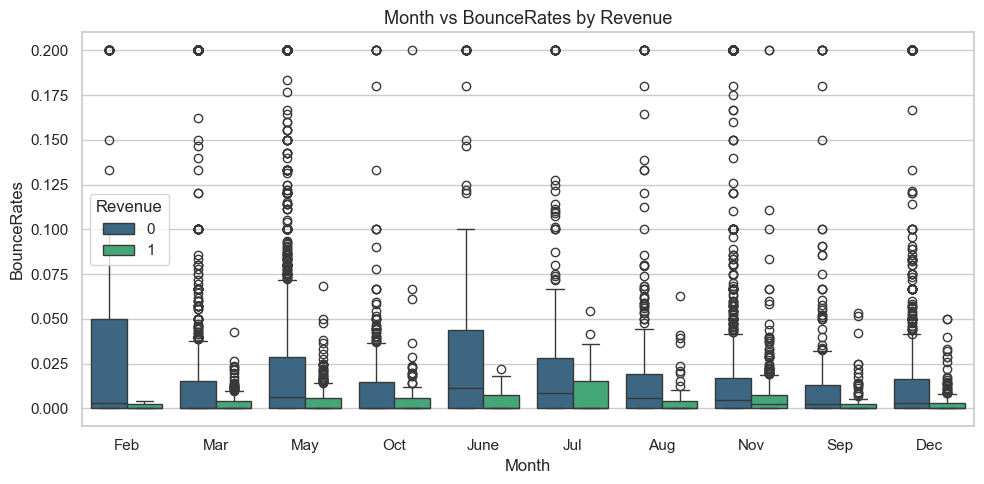

In [139]:
plt.figure(figsize=(10, 5))
sns.boxplot(x="Month", y="BounceRates", hue="Revenue", data=df2, palette="viridis")
plt.title("Month vs BounceRates by Revenue", fontsize=13)
plt.tight_layout()
plt.show()

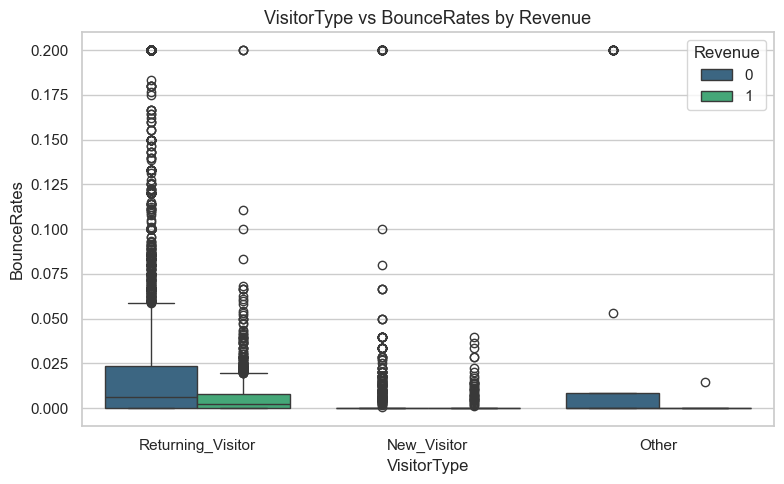

In [140]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="VisitorType", y="BounceRates", hue="Revenue", data=df2, palette="viridis")
plt.title("VisitorType vs BounceRates by Revenue", fontsize=13)
plt.tight_layout()
plt.show()

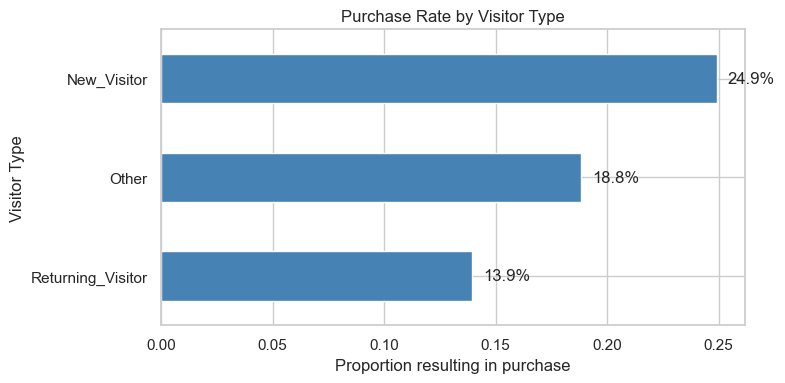

In [141]:
# Purchase rate by visitor type (proportion)
purchase_rate = df2.groupby("VisitorType")["Revenue"].mean().sort_values()

plt.figure(figsize=(8, 4))
purchase_rate.plot(kind="barh", color="steelblue")
for i, v in enumerate(purchase_rate):
    plt.text(v + 0.005, i, f"{v:.1%}", va="center")
plt.title("Purchase Rate by Visitor Type")
plt.xlabel("Proportion resulting in purchase")
plt.ylabel("Visitor Type")
plt.tight_layout()
plt.show()

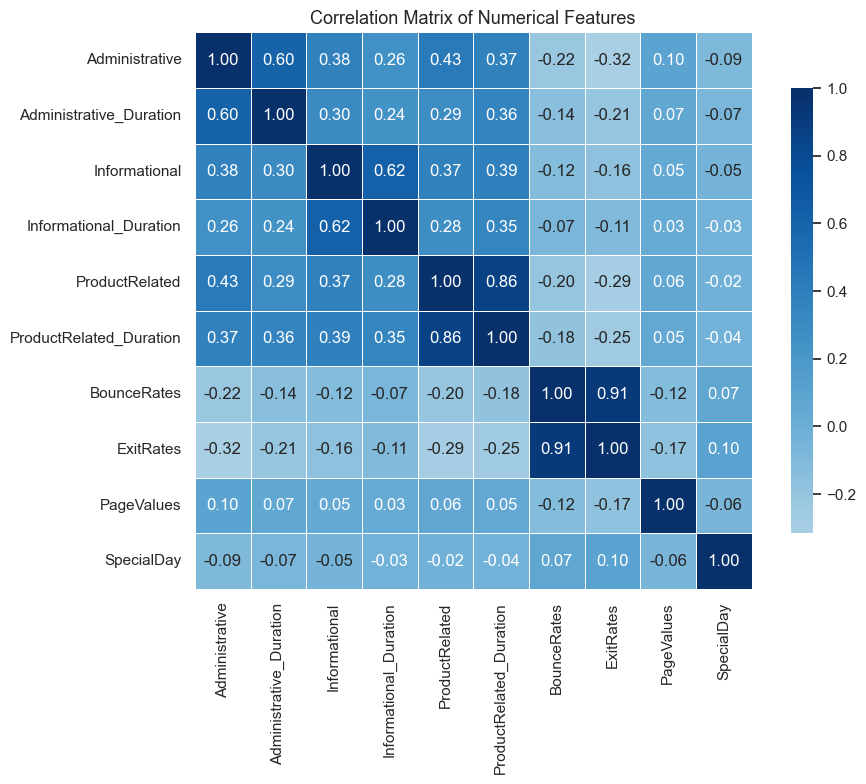

In [142]:
# Correlation matrix of the ten numerical attributes
numerical_cols = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay",
]

corr = df2[numerical_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
)
plt.title("Correlation Matrix of Numerical Features", fontsize=13)
plt.tight_layout()
plt.show()

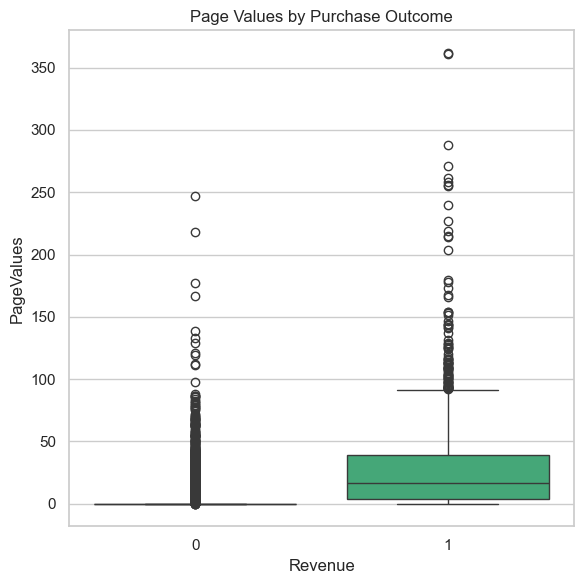

In [143]:
plt.figure(figsize=(6, 6))
sns.boxplot(x="Revenue", y="PageValues", hue="Revenue",
            data=df2, palette="viridis", legend=False)
plt.title("Page Values by Purchase Outcome")
plt.xlabel("Revenue")
plt.ylabel("PageValues")
plt.tight_layout()
plt.show()

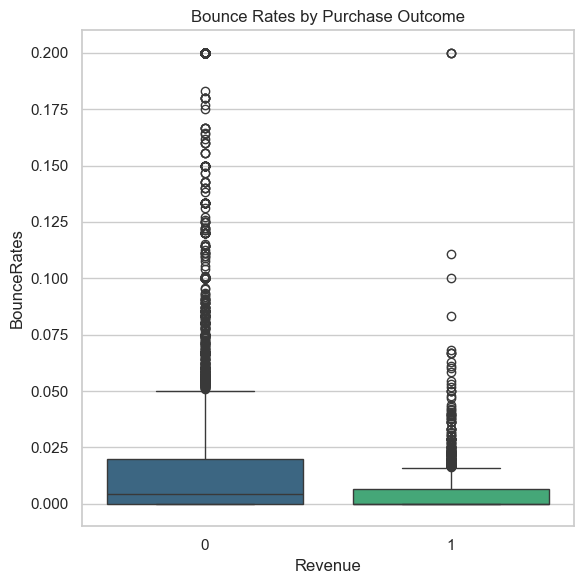

In [144]:
plt.figure(figsize=(6, 6))
sns.boxplot(x="Revenue", y="BounceRates", hue="Revenue",
            data=df2, palette="viridis", legend=False)
plt.title("Bounce Rates by Purchase Outcome")
plt.xlabel("Revenue")
plt.ylabel("BounceRates")
plt.tight_layout()
plt.show()

In [145]:
y

0        0
1        0
2        0
3        0
4        0
        ..
12325    0
12326    0
12327    0
12328    0
12329    0
Name: Revenue, Length: 12330, dtype: int64

# Section 3.3 — Clustering

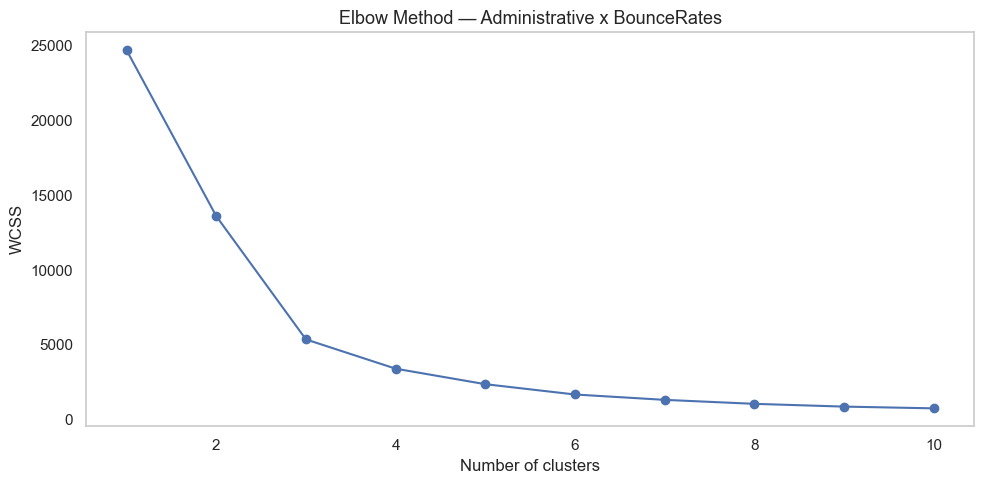

In [146]:
X_clust = df2[["Administrative", "BounceRates"]].values
X_clust = StandardScaler().fit_transform(X_clust)

wcss = []
for i in range(1, 11):
    km = KMeans(n_clusters=i, init="k-means++", n_init=10,
                max_iter=300, random_state=RANDOM_STATE)
    km.fit(X_clust)
    wcss.append(km.inertia_)

plt.figure(figsize=(10, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.grid()
plt.title("Elbow Method — Administrative x BounceRates", fontsize=13)
plt.xlabel("Number of clusters")
plt.ylabel("WCSS")
plt.tight_layout()
plt.show()

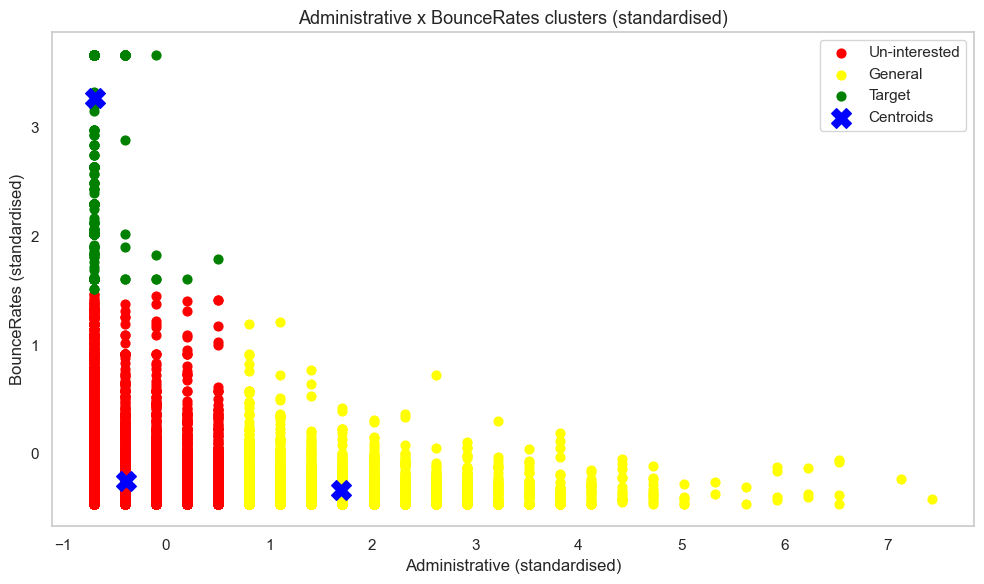

In [147]:
km = KMeans(n_clusters=3, init="k-means++", n_init=10,
            max_iter=300, random_state=RANDOM_STATE)
y_means = km.fit_predict(X_clust)

plt.figure(figsize=(10, 6))
plt.scatter(X_clust[y_means == 0, 0], X_clust[y_means == 0, 1],
            s=40, c="red", label="Un-interested")
plt.scatter(X_clust[y_means == 1, 0], X_clust[y_means == 1, 1],
            s=40, c="yellow", label="General")
plt.scatter(X_clust[y_means == 2, 0], X_clust[y_means == 2, 1],
            s=40, c="green", label="Target")
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
            s=200, c="blue", marker="X", label="Centroids")
plt.title("Administrative x BounceRates clusters (standardised)", fontsize=13)
plt.grid()
plt.xlabel("Administrative (standardised)")
plt.ylabel("BounceRates (standardised)")
plt.legend()
plt.tight_layout()
plt.show()

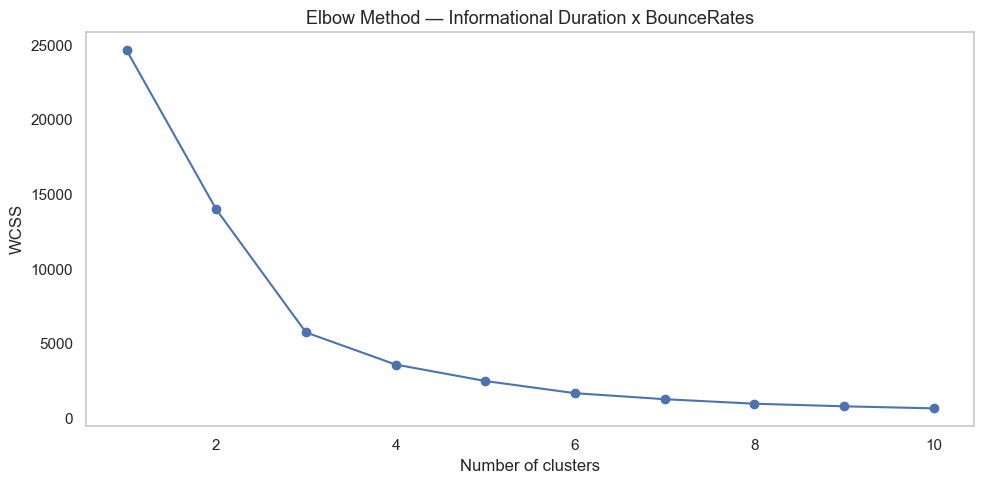

In [148]:
X_clust2 = df2[["Informational_Duration", "BounceRates"]].values
X_clust2 = StandardScaler().fit_transform(X_clust2)

wcss = []
for i in range(1, 11):
    km = KMeans(n_clusters=i, init="k-means++", n_init=10,
                max_iter=300, random_state=RANDOM_STATE)
    km.fit(X_clust2)
    wcss.append(km.inertia_)

plt.figure(figsize=(10, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.grid()
plt.title("Elbow Method — Informational Duration x BounceRates", fontsize=13)
plt.xlabel("Number of clusters")
plt.ylabel("WCSS")
plt.tight_layout()
plt.show()

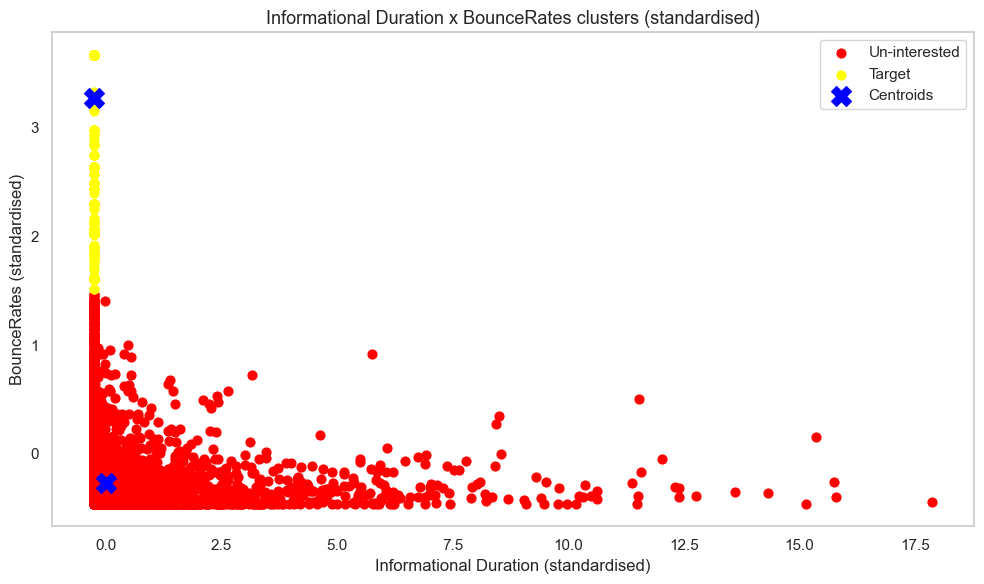

In [149]:
km = KMeans(n_clusters=2, init="k-means++", n_init=10,
            max_iter=300, random_state=RANDOM_STATE)
y_means = km.fit_predict(X_clust2)

plt.figure(figsize=(10, 6))
plt.scatter(X_clust2[y_means == 0, 0], X_clust2[y_means == 0, 1],
            s=40, c="red", label="Un-interested")
plt.scatter(X_clust2[y_means == 1, 0], X_clust2[y_means == 1, 1],
            s=40, c="yellow", label="Target")
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
            s=200, c="blue", marker="X", label="Centroids")
plt.title("Informational Duration x BounceRates clusters (standardised)", fontsize=13)
plt.grid()
plt.xlabel("Informational Duration (standardised)")
plt.ylabel("BounceRates (standardised)")
plt.legend()
plt.tight_layout()
plt.show()

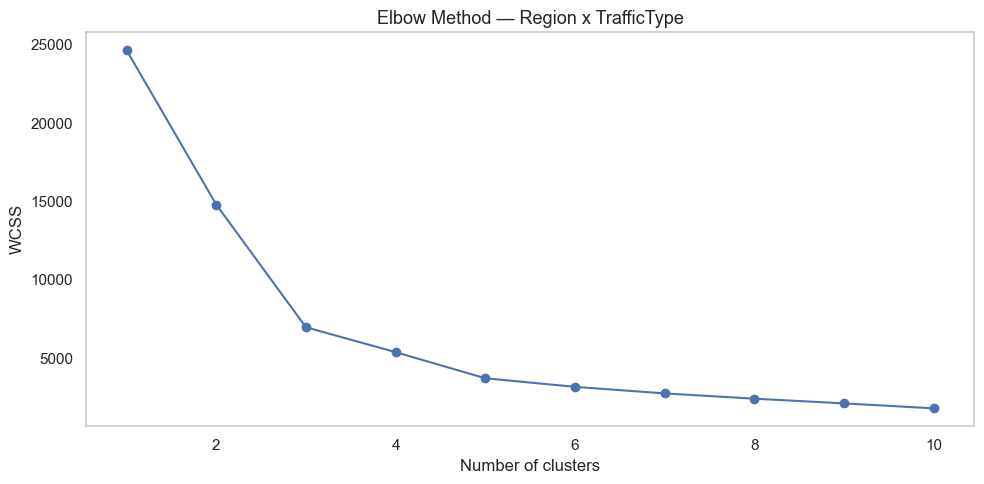

In [150]:
X_clust3 = df2[["Region", "TrafficType"]].values
X_clust3 = StandardScaler().fit_transform(X_clust3)

wcss = []
for i in range(1, 11):
    km = KMeans(n_clusters=i, init="k-means++", n_init=10,
                max_iter=300, random_state=RANDOM_STATE)
    km.fit(X_clust3)
    wcss.append(km.inertia_)

plt.figure(figsize=(10, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.grid()
plt.title("Elbow Method — Region x TrafficType", fontsize=13)
plt.xlabel("Number of clusters")
plt.ylabel("WCSS")
plt.tight_layout()
plt.show()

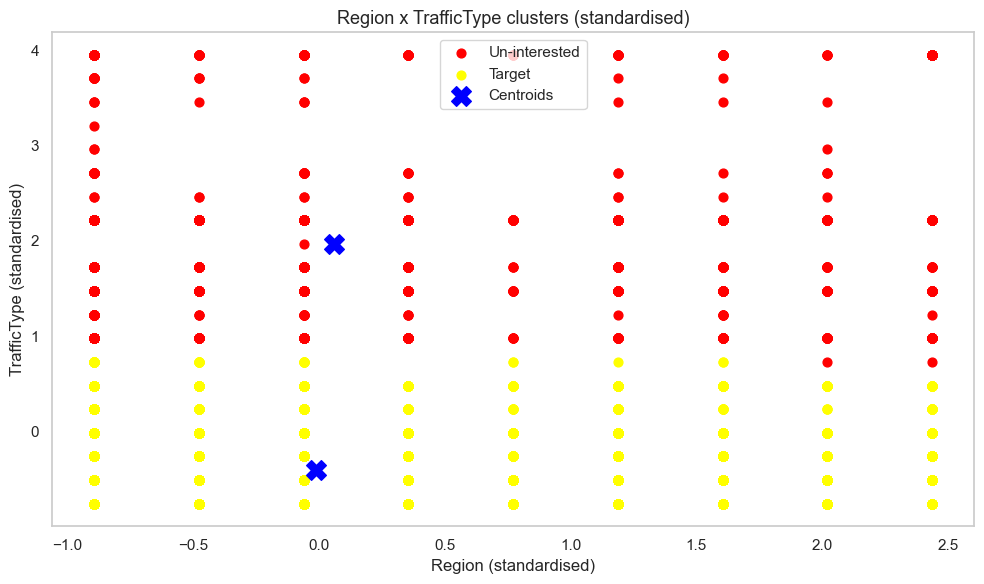

In [151]:
km = KMeans(n_clusters=2, init="k-means++", n_init=10,
            max_iter=300, random_state=RANDOM_STATE)
y_means = km.fit_predict(X_clust3)

plt.figure(figsize=(10, 6))
plt.scatter(X_clust3[y_means == 0, 0], X_clust3[y_means == 0, 1],
            s=40, c="red", label="Un-interested")
plt.scatter(X_clust3[y_means == 1, 0], X_clust3[y_means == 1, 1],
            s=40, c="yellow", label="Target")
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
            s=200, c="blue", marker="X", label="Centroids")
plt.title("Region x TrafficType clusters (standardised)", fontsize=13)
plt.grid()
plt.xlabel("Region (standardised)")
plt.ylabel("TrafficType (standardised)")
plt.legend()
plt.tight_layout()
plt.show()

# Section 3.4 — Predictive Modelling (Multi-Model Pipeline)

In [152]:
models = {
    "Logistic Regression": LogisticRegression(
        solver="liblinear", class_weight="balanced",
        random_state=RANDOM_STATE, max_iter=1000,
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=RANDOM_STATE, max_depth=10,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "AdaBoost": AdaBoostClassifier(
        n_estimators=200, random_state=RANDOM_STATE,
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=3,
        random_state=RANDOM_STATE,
    ),
    "Naive Bayes": GaussianNB(),
    "MLP": MLPClassifier(
        hidden_layer_sizes=(64, 32), max_iter=500,
        random_state=RANDOM_STATE,
    ),
}

In [ ]:
sample_weights = np.where(y_train == 1, 5.5, 1.0)

fitted = {}
for name, model in models.items():
    if name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        proba = model.predict_proba(X_test_scaled)[:, 1]
        pred = model.predict(X_test_scaled)
    elif name in ("AdaBoost", "Gradient Boosting", "Naive Bayes"):
        model.fit(X_train, y_train, sample_weight=sample_weights)
        proba = model.predict_proba(X_test)[:, 1]
        pred = model.predict(X_test)
    else:
        model.fit(X_train, y_train)
        proba = model.predict_proba(X_test)[:, 1]
        pred = model.predict(X_test)

    fitted[name] = {"model": model, "pred": pred, "proba": proba}

In [158]:
results = []
for name, out in fitted.items():
    y_pred = out["pred"]
    y_proba = out["proba"]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (minority)": precision_score(y_test, y_pred),
        "Recall (minority)": recall_score(y_test, y_pred),
        "F1 (minority)": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "Brier": brier_score_loss(y_test, y_proba),
    })

results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df.sort_values("ROC-AUC", ascending=False)

,Accuracy,Precision (minority),Recall (minority),F1 (minority),ROC-AUC,Brier
Model,,,,,,
Gradient Boosting,0.8693,0.5499,0.8553,0.6694,0.9345,0.1004
Random Forest,0.9046,0.7668,0.5514,0.6415,0.9276,0.0696
AdaBoost,0.8647,0.5418,0.8155,0.6510,0.9177,0.1769
Logistic Regression,0.8586,0.5304,0.7505,0.6215,0.9033,0.1189
MLP,0.8583,0.5433,0.5262,0.5346,0.8738,0.1169
Decision Tree,0.8440,0.4973,0.7652,0.6028,0.8515,0.1206
Naive Bayes,0.7139,0.3130,0.7107,0.4346,0.8026,0.2284


In [155]:
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.base import clone

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scaled_models   = {"Logistic Regression", "MLP"}              # MLP scaled here, see note below
weighted_models = {"AdaBoost", "Gradient Boosting", "Naive Bayes"}

rows = []
for name, model in models.items():
    for fold, (tr, te) in enumerate(skf.split(X, y), start=1):
        X_tr, X_te = X.iloc[tr], X.iloc[te]
        y_tr, y_te = y.iloc[tr], y.iloc[te]

        m = clone(model)
        if name in scaled_models:
            m = make_pipeline(StandardScaler(), m)

        if name in weighted_models:
            w = np.where(y_tr == 1, 5.5, 1.0)
            m.fit(X_tr, y_tr, sample_weight=w)
        else:
            m.fit(X_tr, y_tr)

        proba = m.predict_proba(X_te)[:, 1]
        pred  = m.predict(X_te)

        rows.append({
            "Model": name, "Fold": fold,
            "AUC": roc_auc_score(y_te, proba),
            "F1": f1_score(y_te, pred),
            "Recall": recall_score(y_te, pred),
            "Precision": precision_score(y_te, pred),
            "Brier": brier_score_loss(y_te, proba),
        })

cv_df = pd.DataFrame(rows)

summary = (cv_df.groupby("Model")[["AUC", "F1", "Recall", "Precision", "Brier"]]
                .agg(["mean", "std"]).round(4))
print(summary.sort_values(("AUC", "mean"), ascending=False))

# Fold-by-fold comparison of the two models in question
auc = cv_df.pivot(index="Fold", columns="Model", values="AUC")
diff = auc["Gradient Boosting"] - auc["Random Forest"]
print("\nAUC difference (GB - RF) per fold:\n", diff.round(4))
print("Mean difference:", round(diff.mean(), 4),
      "| Std:", round(diff.std(), 4),
      "| GB higher in", int((diff > 0).sum()), "of 5 folds")

c:\Users\user\anaconda3\envs\msc_env\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


                        AUC              F1          Recall         Precision  \
                       mean     std    mean     std    mean     std      mean   
Model                                                                           
Gradient Boosting    0.9322  0.0031  0.6577  0.0054  0.8443  0.0148    0.5388   
Random Forest        0.9306  0.0038  0.6298  0.0239  0.5419  0.0317    0.7532   
AdaBoost             0.9185  0.0030  0.6509  0.0164  0.8145  0.0083    0.5423   
Logistic Regression  0.9043  0.0049  0.6148  0.0041  0.7641  0.0077    0.5143   
MLP                  0.8825  0.0110  0.5763  0.0192  0.5723  0.0312    0.5825   
Decision Tree        0.8678  0.0171  0.6177  0.0177  0.7914  0.0289    0.5068   
Naive Bayes          0.8174  0.0067  0.4583  0.0050  0.7537  0.0169    0.3294   

                              Brier          
                        std    mean     std  
Model                                        
Gradient Boosting    0.0081  0.1024  0.0040  
Rando

In [156]:
summary

AUC              F1          Recall         Precision  \
                       mean     std    mean     std    mean     std      mean   
Model                                                                           
AdaBoost             0.9185  0.0030  0.6509  0.0164  0.8145  0.0083    0.5423   
Decision Tree        0.8678  0.0171  0.6177  0.0177  0.7914  0.0289    0.5068   
Gradient Boosting    0.9322  0.0031  0.6577  0.0054  0.8443  0.0148    0.5388   
Logistic Regression  0.9043  0.0049  0.6148  0.0041  0.7641  0.0077    0.5143   
MLP                  0.8825  0.0110  0.5763  0.0192  0.5723  0.0312    0.5825   
Naive Bayes          0.8174  0.0067  0.4583  0.0050  0.7537  0.0169    0.3294   
Random Forest        0.9306  0.0038  0.6298  0.0239  0.5419  0.0317    0.7532   

                              Brier          
                        std    mean     std  
Model                                        
AdaBoost             0.0220  0.1769  0.0031  
Decision Tree        0.0170  0.1177  0.0071  
Gradient Boosting    0.0081  0.1024  0.0040  
Logistic Regression  0.0044  0.1208  0.0013  
MLP                  0.0368  0.1107  0.0063  
Naive Bayes          0.0050  0.2197  0.0034  
Random Forest        0.0274  0.0697  0.0016

In [ ]:
# results_df.to_csv("Model Performance.csv")

In [32]:
for name, out in fitted.items():
    print(f"--- {name} ---")
    print(classification_report(y_test, out["pred"], digits=4))
    print()

--- Logistic Regression ---
              precision    recall  f1-score   support

           0     0.9506    0.8784    0.9130      2606
           1     0.5304    0.7505    0.6215       477

    accuracy                         0.8586      3083
   macro avg     0.7405    0.8144    0.7673      3083
weighted avg     0.8856    0.8586    0.8679      3083


--- Decision Tree ---
              precision    recall  f1-score   support

           0     0.9523    0.8584    0.9029      2606
           1     0.4973    0.7652    0.6028       477

    accuracy                         0.8440      3083
   macro avg     0.7248    0.8118    0.7529      3083
weighted avg     0.8819    0.8440    0.8565      3083


--- Random Forest ---
              precision    recall  f1-score   support

           0     0.9219    0.9693    0.9450      2606
           1     0.7668    0.5514    0.6415       477

    accuracy                         0.9046      3083
   macro avg     0.8443    0.7603    0.7932      3083


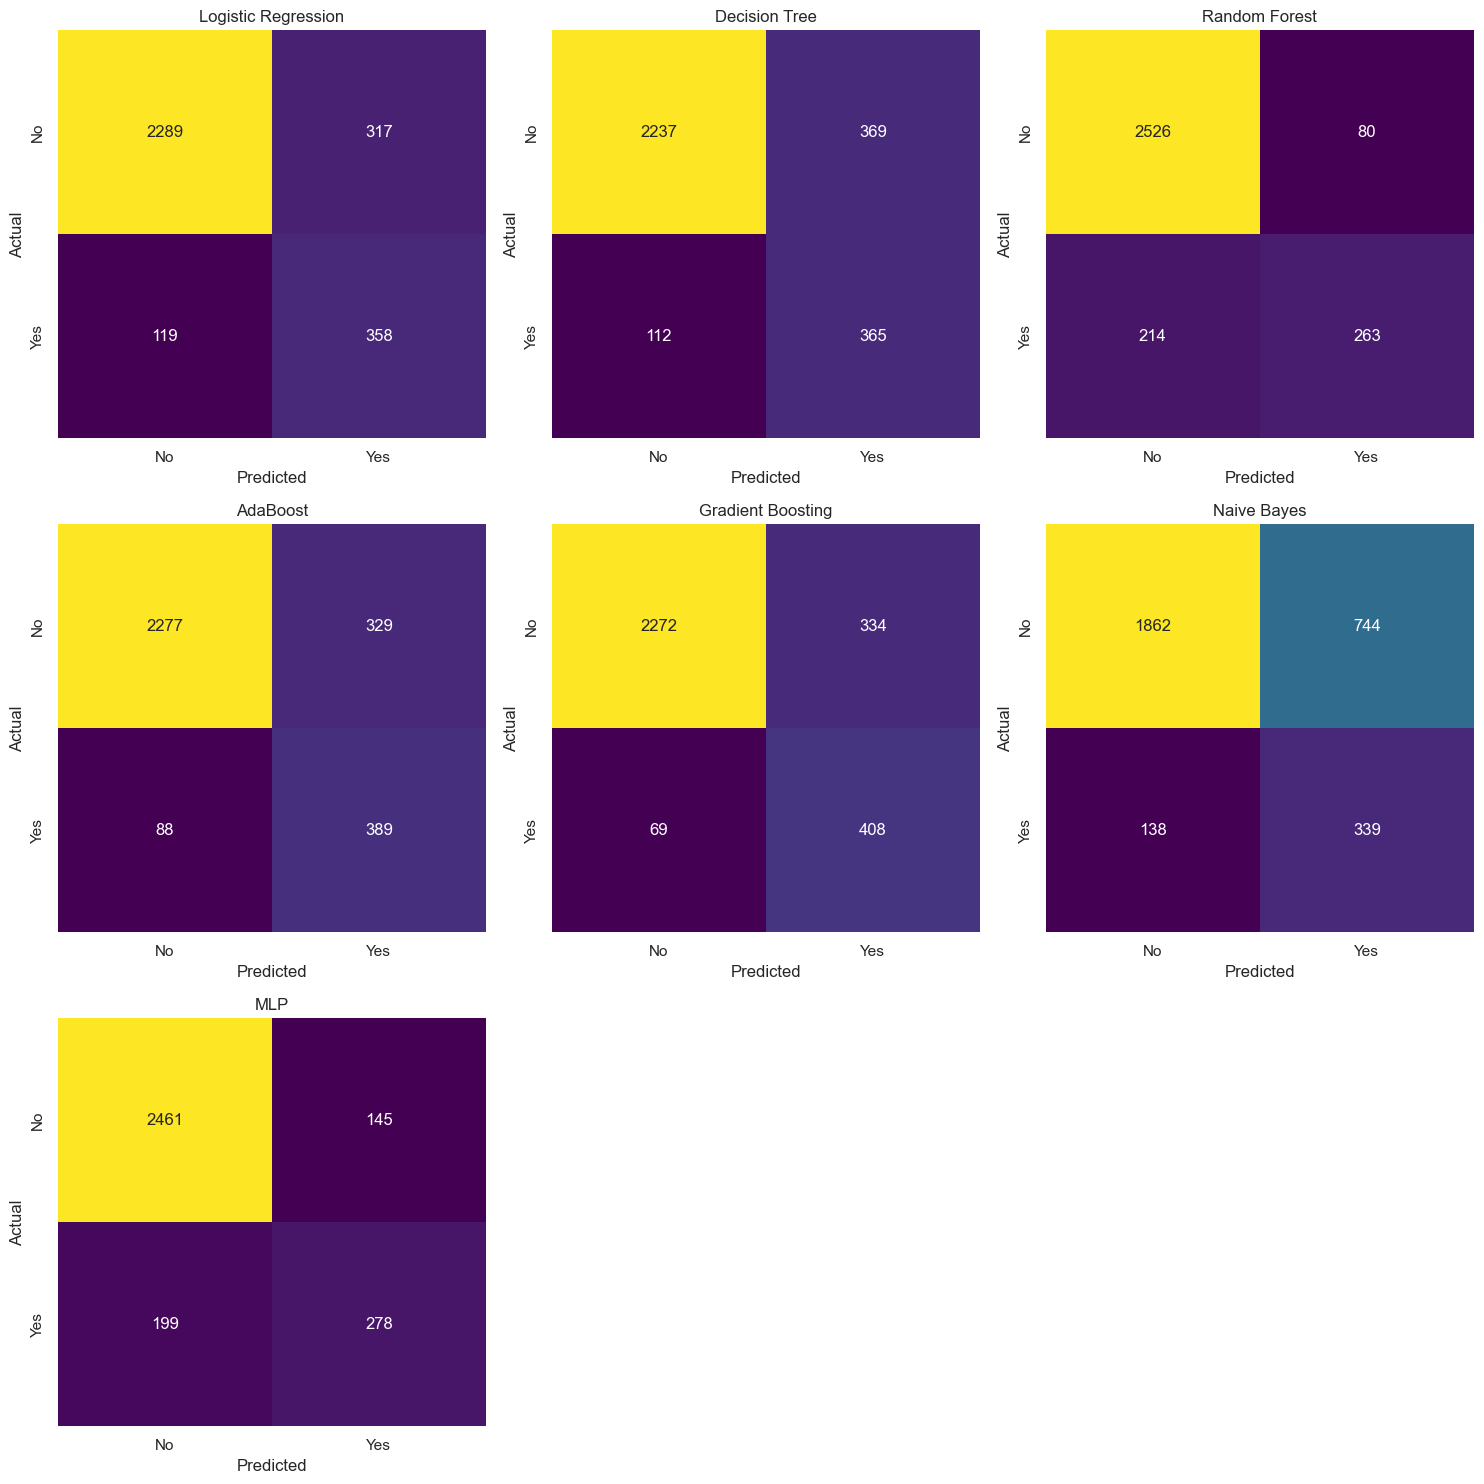

In [33]:
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
axes = axes.flatten()

for ax, (name, out) in zip(axes, fitted.items()):
    cm = confusion_matrix(y_test, out["pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="viridis", cbar=False, ax=ax,
                xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

for ax in axes[len(fitted):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

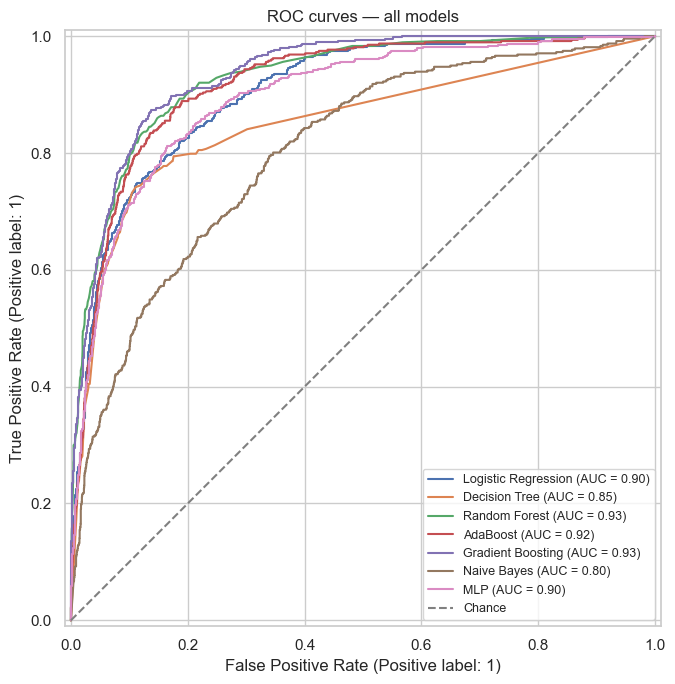

In [34]:
fig, ax = plt.subplots(figsize=(8, 7))
for name, out in fitted.items():
    if name == "Logistic Regression":
        RocCurveDisplay.from_estimator(out["model"], X_test_scaled, y_test, ax=ax, name=name)
    else:
        RocCurveDisplay.from_estimator(out["model"], X_test, y_test, ax=ax, name=name)

ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Chance")
ax.set_title("ROC curves — all models")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

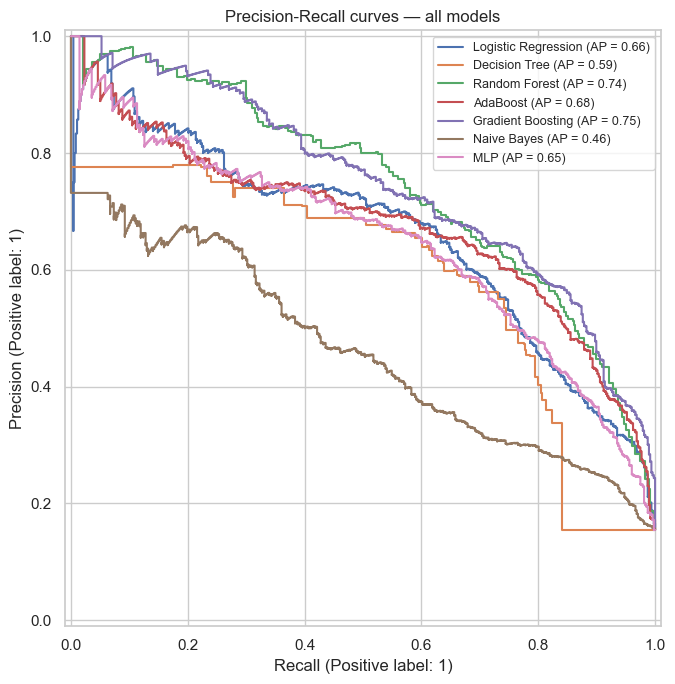

In [35]:
fig, ax = plt.subplots(figsize=(8, 7))
for name, out in fitted.items():
    PrecisionRecallDisplay.from_predictions(y_test, out["proba"], ax=ax, name=name)

ax.set_title("Precision-Recall curves — all models")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

In [36]:
thresholds = np.linspace(0.05, 0.95, 19)

rows = []
for name, out in fitted.items():
    for t in thresholds:
        pred_t = (out["proba"] >= t).astype(int)
        rows.append({
            "Model": name,
            "Threshold": round(t, 2),
            "Precision": precision_score(y_test, pred_t, zero_division=0),
            "Recall": recall_score(y_test, pred_t, zero_division=0),
            "F1": f1_score(y_test, pred_t, zero_division=0),
        })

threshold_df = pd.DataFrame(rows)
threshold_df.head()

,Model,Threshold,Precision,Recall,F1
0,Logistic Regression,0.05,0.171717,0.997904,0.293013
1,Logistic Regression,0.10,0.188469,0.993711,0.316845
2,Logistic Regression,0.15,0.220093,0.987421,0.359954
3,Logistic Regression,0.20,0.266515,0.981132,0.419167
4,Logistic Regression,0.25,0.309264,0.951782,0.466838


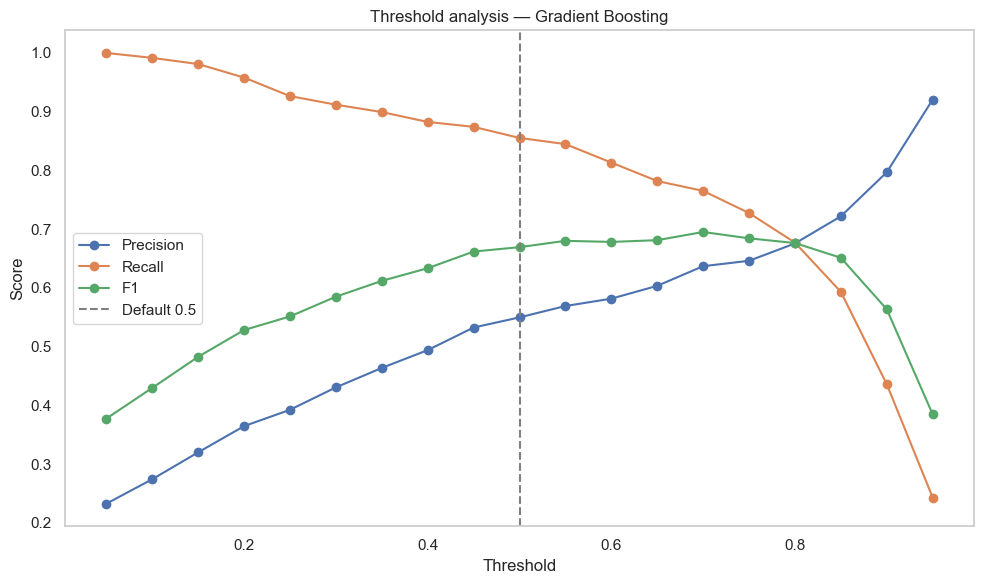

In [37]:
best_model_name = results_df["F1 (minority)"].idxmax()
sub = threshold_df[threshold_df["Model"] == best_model_name]

plt.figure(figsize=(10, 6))
plt.plot(sub["Threshold"], sub["Precision"], marker="o", label="Precision")
plt.plot(sub["Threshold"], sub["Recall"], marker="o", label="Recall")
plt.plot(sub["Threshold"], sub["F1"], marker="o", label="F1")
plt.axvline(0.5, linestyle="--", color="grey", label="Default 0.5")
plt.title(f"Threshold analysis — {best_model_name}")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

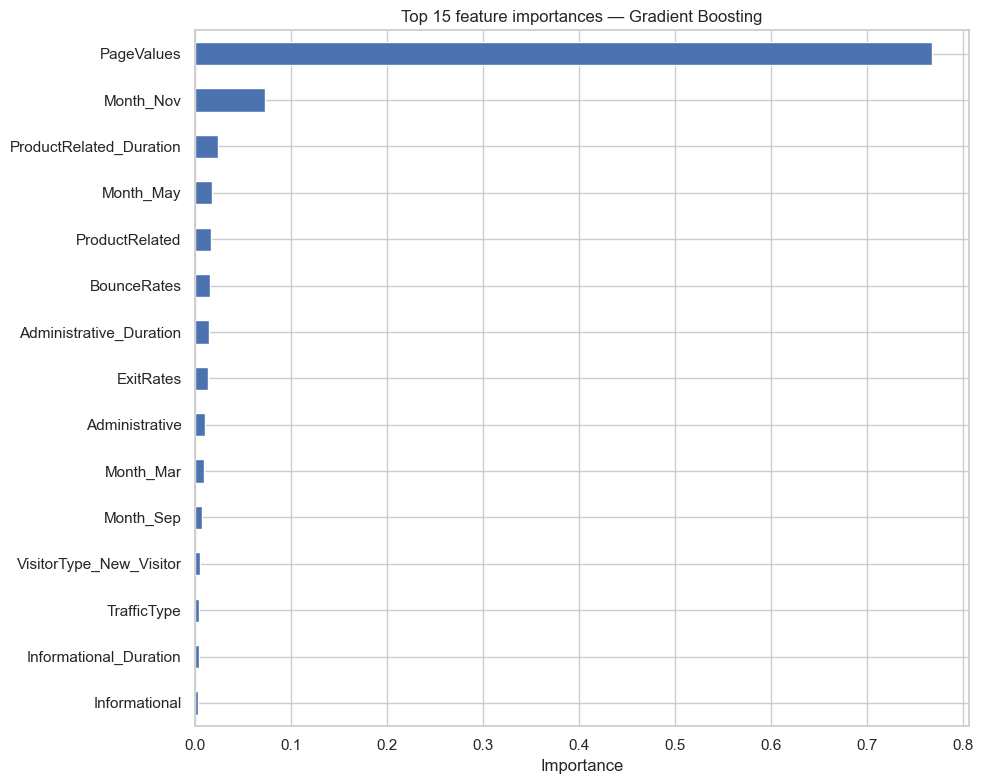

In [38]:
if hasattr(fitted[best_model_name]["model"], "feature_importances_"):
    importances = pd.Series(
        fitted[best_model_name]["model"].feature_importances_,
        index=X.columns,
    ).sort_values(ascending=False)

    plt.figure(figsize=(10, 8))
    importances.head(15).plot(kind="barh")
    plt.gca().invert_yaxis()
    plt.title(f"Top 15 feature importances — {best_model_name}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
else:
    print(f"{best_model_name} does not expose feature_importances_; "
          "use permutation importance or SHAP instead.")

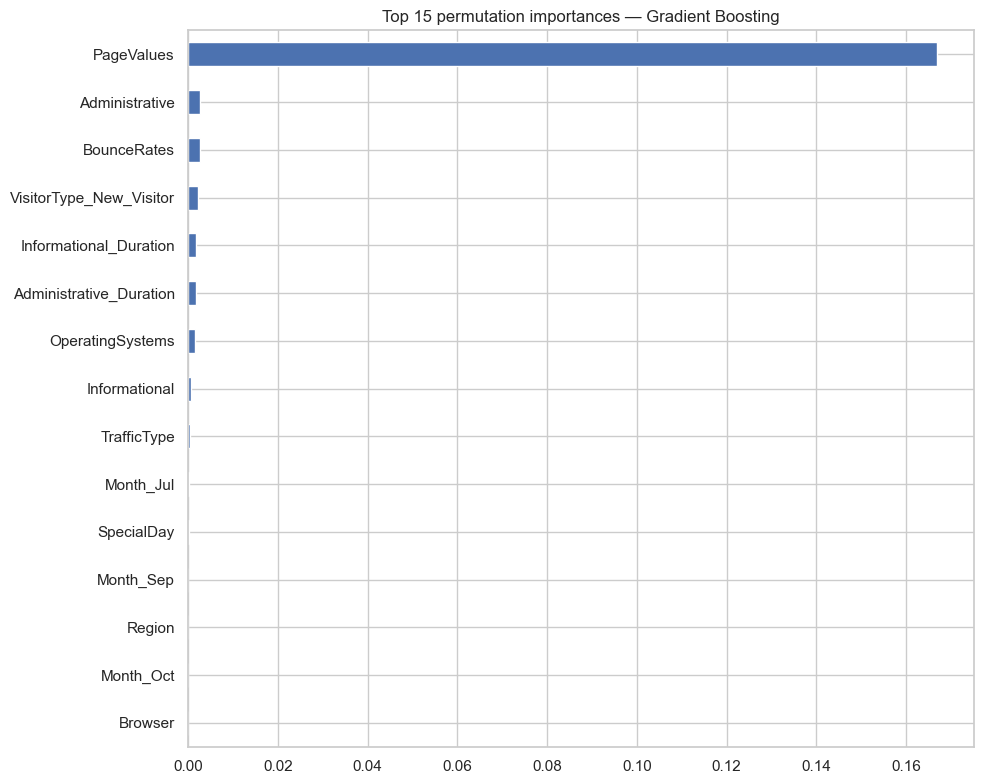

In [39]:
from sklearn.inspection import permutation_importance

best_out = fitted[best_model_name]
X_eval = X_test_scaled if best_model_name == "Logistic Regression" else X_test

perm = permutation_importance(
    best_out["model"], X_eval, y_test,
    n_repeats=10, random_state=RANDOM_STATE,
)

perm_df = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
perm_df.head(15).plot(kind="barh")
plt.gca().invert_yaxis()
plt.title(f"Top 15 permutation importances — {best_model_name}")
plt.tight_layout()
plt.show()